**CCGT Case Study 3: Economics**

This notebook turns the model's performance into money: the **levelized cost of electricity** (LCOE), its sensitivity to fuel price, capacity factor and carbon price, and the value of the steam cycle compared with running the gas turbine alone (**simple cycle**).

$$LCOE = \underbrace{\frac{CAPEX \cdot CRF + \text{fixed O\&M}}{8760 \cdot CF}}_{\text{fixed costs}} + \underbrace{HR \cdot p_{fuel} + \text{variable O\&M} + e_{CO_2}\, p_{CO_2}}_{\text{marginal cost}}, \qquad CRF = \frac{i(1+i)^n}{(1+i)^n - 1}$$

The heat rate $HR$ and the CO₂ intensity $e_{CO_2}$ come from the IDAES model. The simple cycle case is the same gas turbine without the HRSG and steam cycle.

> **Assumptions** (in `ECONOMICS`, `ccgt_case_studies.py`; change them to suit your project)
>
> | | Combined cycle | Simple cycle |
> |---|---|---|
> | CAPEX | 1100 $/kW | 750 $/kW |
> | Fixed O&M | 18 $/kW-yr | 12 $/kW-yr |
> | Variable O&M | 3.5 $/MWh | 5.0 $/MWh |
>
> Discount rate 8 %, 25 year life, fuel 6 $/MMBtu (LHV), capacity factor 60 %, no carbon price. These are indicative values for small industrial plants, not quotes.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ccgt import setup_ccgt_model, set_mode, ccgt_results
from ccgt_case_studies import solve, ECONOMICS, plant_cases

model, results = setup_ccgt_model()
set_mode(model, "targets")
solve(model)
kpi = ccgt_results(model)
pd.DataFrame(plant_cases(kpi)).round(1)

2026-11-12 16:52:34 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:52:34 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:52:34 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:52:35 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.control_volume.properties_in[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


2026-11-12 16:52:35 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.control_volume.properties_out[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


2026-11-12 16:52:35 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.properties_isentropic[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


... (43 outputs left out)

2026-11-12 16:52:35 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.economizer.cold_side.heat


2026-11-12 16:52:35 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.condenser.control_volume.heat


The DOF is 0


,Combined cycle,Simple cycle
Net power (kW),27113.3,18618.0
Heat rate (kJ/kWh),6419.6,9348.8
CO2 (kg/MWh),362.1,527.3


## LCOE breakdown: combined vs simple cycle

,Combined cycle,Simple cycle
Capital,19.61,13.37
Fixed O&M,3.42,2.28
Fuel,36.51,53.17
Variable O&M,3.50,5.00
Carbon,0.00,0.00
LCOE,63.04,73.82


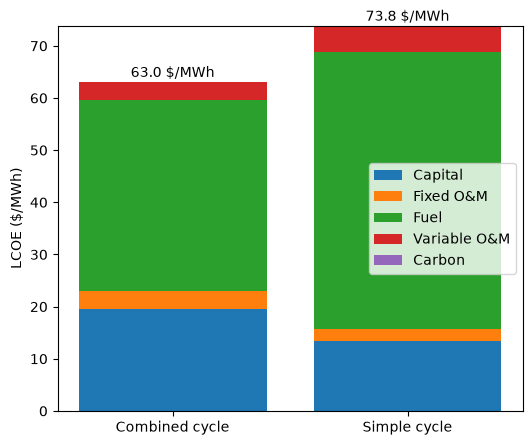

In [3]:
from ccgt_case_studies import lcoe_table

table = lcoe_table(kpi)
display(table.round(2))
parts = ["Capital", "Fixed O&M", "Fuel", "Variable O&M", "Carbon"]
fig, ax = plt.subplots(figsize=(6, 5))
bottom = np.zeros(2)
for p in parts:
    ax.bar(table.columns, table.loc[p], bottom=bottom, label=p)
    bottom += table.loc[p].values
for i, v in enumerate(table.loc["LCOE"]):
    ax.text(i, v + 1, "{0:.1f} $/MWh".format(v), ha="center")
ax.set_ylabel("LCOE ($/MWh)")
ax.legend()
plt.show()

The steam cycle adds about 45 % more power from the same fuel. It costs more to build, but fuel dominates the cost of electricity from gas, so at a 60 % capacity factor the combined cycle is about 11 $/MWh cheaper.

## Fuel price and capacity factor

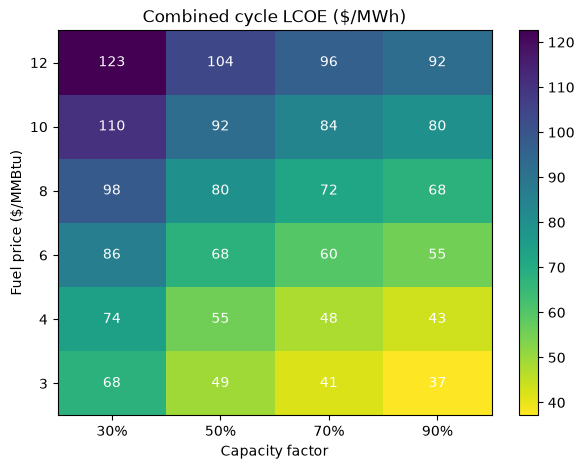

In [4]:
from ccgt_case_studies import lcoe_heatmap

heat = lcoe_heatmap(kpi)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(heat.values, cmap="viridis_r", aspect="auto", origin="lower")
ax.set_xticks(range(len(heat.columns)), ["{0:.0%}".format(c) for c in heat.columns])
ax.set_yticks(range(len(heat.index)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, "{0:.0f}".format(heat.values[i, j]), ha="center", va="center", color="w")
ax.set_xlabel("Capacity factor")
ax.set_ylabel("Fuel price ($/MMBtu)")
ax.set_title("Combined cycle LCOE ($/MWh)")
fig.colorbar(im)
plt.show()

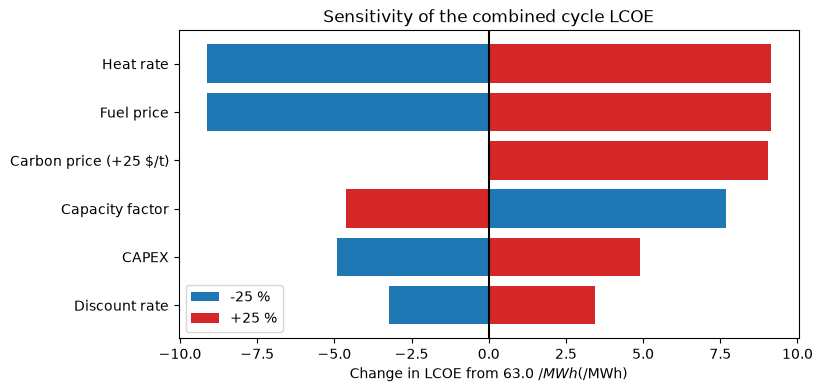

In [5]:
from ccgt_case_studies import tornado

tor, base = tornado(kpi)
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(tor))
ax.barh(y, tor["Low"], color="tab:blue", label="-25 %")
ax.barh(y, tor["High"], color="tab:red", label="+25 %")
ax.set_yticks(y, tor.index)
ax.axvline(0, color="k")
ax.set_xlabel("Change in LCOE from {0:.1f} $/MWh ($/MWh)".format(base))
ax.set_title("Sensitivity of the combined cycle LCOE")
ax.legend()
plt.show()

Fuel price and heat rate have the same, largest effect, because the fuel bill is more than half of the LCOE. So **one point of efficiency is worth about 0.65 $/MWh**, about 90 k$/yr for this plant at 6 $/MMBtu. That is the money behind the efficiency studies in notebooks 1, 2 and 4.

## Carbon price

,Combined cycle,Simple cycle
Carbon price ($/t CO2),,
0,63.0,73.8
25,72.1,87.0
50,81.1,100.2
75,90.2,113.4
100,99.2,126.5
150,117.3,152.9


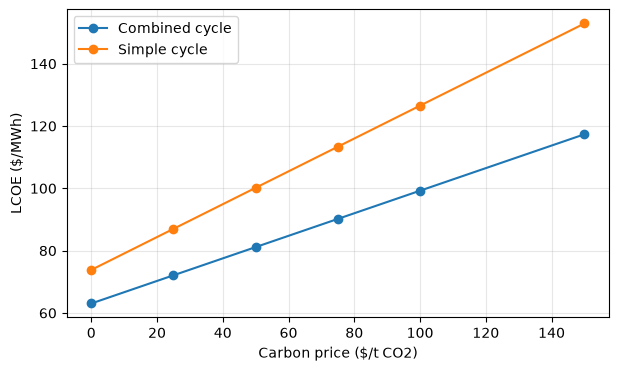

In [6]:
from ccgt_case_studies import carbon_price_study

carbon = carbon_price_study(kpi)
display(carbon.round(1))
fig, ax = plt.subplots(figsize=(7, 4))
for c in carbon.columns:
    ax.plot(carbon.index, carbon[c], "o-", label=c)
ax.set_xlabel("Carbon price ($/t CO2)")
ax.set_ylabel("LCOE ($/MWh)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

The combined cycle emits about 362 kg CO₂/MWh against about 527 kg/MWh for the simple cycle, so a carbon price widens the gap between them: each 25 $/t adds about 9 $/MWh to the combined cycle and 13 $/MWh to the simple cycle.

## Dispatch: spark spread and margin

A plant runs when the power price covers its **marginal cost** (fuel + variable O&M + carbon). The **spark spread** is the power price minus the fuel cost.

In [7]:
from ccgt_case_studies import dispatch_study

for cp in (0, 75):
    d = dispatch_study(kpi, carbon_price=cp)
    be = {p: lcoe_table(kpi, carbon_price=cp).loc[["Fuel", "Variable O&M", "Carbon"], p].sum() for p in ("Combined cycle", "Simple cycle")}
    print("Carbon {0} $/t: break-even power price, combined cycle {1:.1f} $/MWh, simple cycle {2:.1f} $/MWh".format(
        cp, be["Combined cycle"], be["Simple cycle"]))
d = dispatch_study(kpi)
d.pivot(index="Power price ($/MWh)", columns="Plant", values="Margin ($/MWh)").round(1)

Carbon 0 $/t: break-even power price, combined cycle 40.0 $/MWh, simple cycle 58.2 $/MWh
Carbon 75 $/t: break-even power price, combined cycle 67.2 $/MWh, simple cycle 97.7 $/MWh


Plant,Combined cycle,Simple cycle
Power price ($/MWh),,
20,-20.0,-38.2
30,-10.0,-28.2
40,-0.0,-18.2
50,10.0,-8.2
60,20.0,1.8
70,30.0,11.8
80,40.0,21.8
90,50.0,31.8
100,60.0,41.8


## The value of the steam cycle

Generating the combined cycle's annual energy with the simple cycle gas turbine would burn about 45 % more fuel:

In [8]:
from ccgt_case_studies import cc_vs_sc_savings

sav = cc_vs_sc_savings(kpi)
payback = sav["Extra CAPEX of the steam cycle ($)"] / sav["Fuel cost saved ($/yr)"]
display(pd.Series(sav).map("{0:,.0f}".format).to_frame("Value"))
print("Simple payback of the steam cycle on fuel alone: {0:.1f} years".format(payback))

,Value
Annual energy (MWh),"142,507"
Fuel saved (MMBtu/yr),"395,649"
Fuel cost saved ($/yr),"2,373,896"
CO2 avoided (t/yr),"23,544"
Extra CAPEX of the steam cycle ($),"15,861,049"


Simple payback of the steam cycle on fuel alone: 6.7 years
